# 06 — Model Evaluation
**Part D | Milestone 6**

Question: how well do the models from notebook 05 predict drift on a flight they **never saw** — not in training, not in tuning — and where do they fail?

Each fold trains (and tunes `alpha`) on one flight and is scored once on the other. Metrics come from `src/vio_drift/evaluation/metrics.py`; models are fit with the same `fit_model` as `scripts/train_eval.py`, and the numbers are checked against its `results/metrics/err_mag_m.csv`.

| Metric | Meaning |
|---|---|
| MAE | mean absolute error (m) — headline number |
| RMSE | root mean squared error (m) — punishes big misses more |
| R² | share of the test flight's drift variation explained; 0 = no better than its mean |
| bias | mean(prediction − truth); > 0 = over-predicts |

In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

from vio_drift.data.splits import load_splits
from vio_drift.evaluation.metrics import score
from vio_drift.features.build_features import feature_names
from vio_drift.models.ml.data import load_dataset, fold_frames
from vio_drift.models.ml.models import MODELS
from vio_drift.models.ml.train import fit_model

ROOT = Path.cwd().parent
FIG = ROOT / "figures" / "ml"
FIG.mkdir(parents=True, exist_ok=True)
config = yaml.safe_load((ROOT / "configs" / "config.yaml").read_text())
processed = ROOT / config["data"]["processed_dir"]
FEATS = feature_names()
TARGET = "err_mag_m"
NAMES = list(MODELS)

## 1. Fit on one flight, predict the other

For each fold and model: tune (Ridge, Lasso) and fit on the training flight, then predict every window of the held-out flight. Predictions on the training flight are kept too, to measure over-fitting.

In [ ]:
df = load_dataset(processed, config["data"]["sequences"], target=TARGET)
folds = load_splits(processed / "splits.json")

pred_rows, metric_rows = [], []
for fold in folds:
    train, test = fold_frames(df, fold)
    for name in NAMES:
        fm = fit_model(name, train[FEATS], train[TARGET])
        y_hat = fm.model.predict(test[FEATS])
        pred_rows.append(pd.DataFrame({"test_seq": fold.test[0], "model": name,
                                       "t_start_ns": test["t_start_ns"], "y": test[TARGET], "y_hat": y_hat}))
        metric_rows.append({"model": name, "test_seq": fold.test[0], "alpha": fm.alpha,
                            **score(test[TARGET], y_hat),
                            "train_mae": score(train[TARGET], fm.model.predict(train[FEATS]))["mae"]})

preds = pd.concat(pred_rows, ignore_index=True)
metrics = pd.DataFrame(metric_rows)
print(preds.shape)

(5248, 5)


## 2. Held-out metrics

In [ ]:
per_fold = metrics.set_index(["test_seq", "model"])
(per_fold[["alpha", "mae", "rmse", "r2", "bias"]]
 .assign(alpha=lambda d: d["alpha"].map(lambda a: "—" if pd.isna(a) else f"{a:.3g}"),
         mae=lambda d: d["mae"] * 100, rmse=lambda d: d["rmse"] * 100, bias=lambda d: d["bias"] * 100)
 .rename(columns={"mae": "MAE (cm)", "rmse": "RMSE (cm)", "r2": "R²", "bias": "bias (cm)"})
 .round(3))

alpha  MAE (cm)  RMSE (cm)     R²  bias (cm)
test_seq   model                                                 
MH_01_easy mean          —     4.397      5.878 -0.041     -1.172
           ols           —     3.119      4.457  0.401     -0.787
           ridge       316     2.798      3.498  0.631     -0.385
           lasso   0.00215     2.593      3.280  0.676     -0.040
MH_02_easy mean          —     4.653      7.942 -0.022      1.172
           ols           —     2.869      3.851  0.760     -0.202
           ridge      31.6     2.598      3.485  0.803     -0.098
           lasso  0.000464     2.416      3.175  0.837     -0.198

In [ ]:
mean = metrics.groupby("model", sort=False)[["mae", "rmse", "r2", "bias", "train_mae"]].mean()
summary = pd.DataFrame({
    "MAE (cm)": mean["mae"] * 100,
    "RMSE (cm)": mean["rmse"] * 100,
    "R²": mean["r2"],
    "bias (cm)": mean["bias"] * 100,
    "MAE vs mean baseline": 1 - mean["mae"] / mean.loc["mean", "mae"],
})
summary.round(3)

,MAE (cm),RMSE (cm),R²,bias (cm),MAE vs mean baseline
model,,,,,
mean,4.525,6.910,-0.032,-0.000,0.000
ols,2.994,4.154,0.580,-0.494,0.338
ridge,2.698,3.491,0.717,-0.241,0.404
lasso,2.504,3.227,0.756,-0.119,0.447


In [ ]:
# Same numbers as scripts/train_eval.py?
saved = pd.read_csv(ROOT / "results" / "metrics" / f"{TARGET}.csv")
saved = saved[saved["fold_id"] != "mean"].set_index(["test_seq", "model"])
cols = ["mae", "rmse", "r2", "bias", "train_mae"]
assert np.allclose(per_fold[cols].sort_index(), saved[cols].sort_index()), "notebook and script disagree"
print("matches results/metrics/err_mag_m.csv")

matches results/metrics/err_mag_m.csv


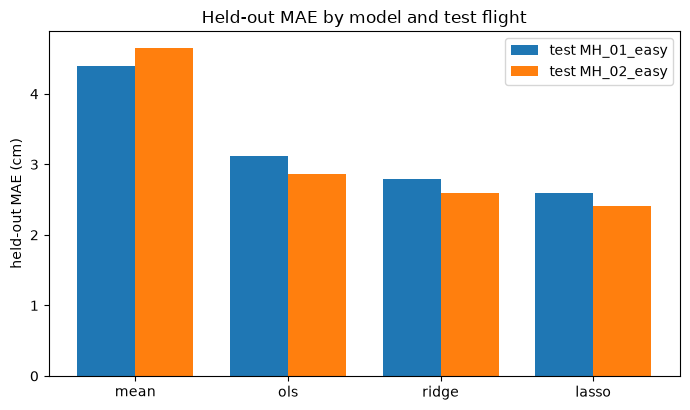

In [ ]:
seqs = list(metrics["test_seq"].unique())
x = np.arange(len(NAMES))
w = 0.38
fig, ax = plt.subplots(figsize=(7, 4.2))
for i, seq in enumerate(seqs):
    vals = metrics[metrics["test_seq"] == seq].set_index("model").loc[NAMES, "mae"] * 100
    ax.bar(x + (i - 0.5) * w, vals, w, label=f"test {seq}")
ax.set_xticks(x, NAMES); ax.set_ylabel("held-out MAE (cm)")
ax.set_title("Held-out MAE by model and test flight")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "heldout_mae_by_model.png", dpi=150); plt.show()

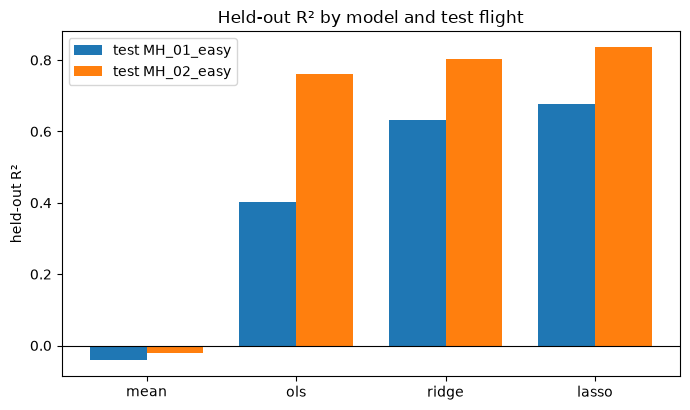

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for i, seq in enumerate(seqs):
    vals = metrics[metrics["test_seq"] == seq].set_index("model").loc[NAMES, "r2"]
    ax.bar(x + (i - 0.5) * w, vals, w, label=f"test {seq}")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x, NAMES); ax.set_ylabel("held-out R²")
ax.set_title("Held-out R² by model and test flight")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "heldout_r2_by_model.png", dpi=150); plt.show()

## 3. Over-fitting: training vs held-out error

A model that fits its training flight much better than the new flight has learned flight-specific noise.

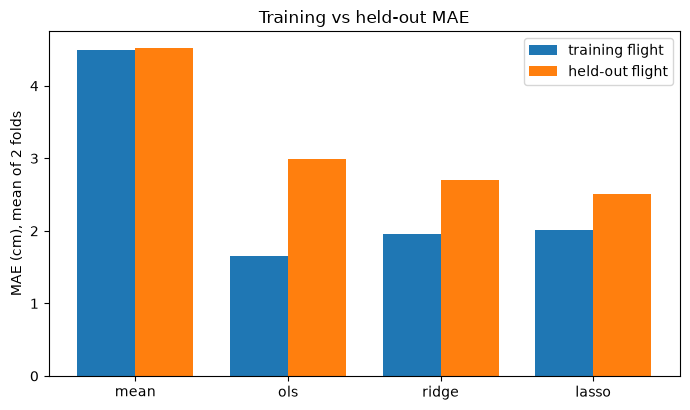

,train MAE (cm),held-out MAE (cm),held-out / train
model,,,
mean,4.50,4.53,1.01
ols,1.65,2.99,1.81
ridge,1.95,2.70,1.38
lasso,2.01,2.50,1.24


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.bar(x - w / 2, mean.loc[NAMES, "train_mae"] * 100, w, label="training flight")
ax.bar(x + w / 2, mean.loc[NAMES, "mae"] * 100, w, label="held-out flight")
ax.set_xticks(x, NAMES); ax.set_ylabel("MAE (cm), mean of 2 folds")
ax.set_title("Training vs held-out MAE")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "train_vs_heldout_mae.png", dpi=150); plt.show()

(mean[["train_mae", "mae"]] * 100).assign(ratio=mean["mae"] / mean["train_mae"]).rename(
    columns={"train_mae": "train MAE (cm)", "mae": "held-out MAE (cm)", "ratio": "held-out / train"}).round(2)

## 4. Lasso, the best model: predictions up close

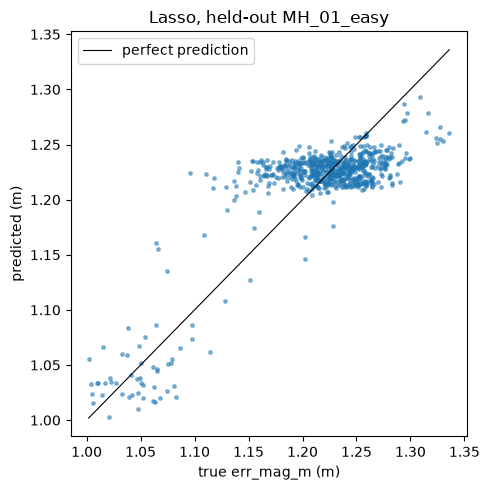

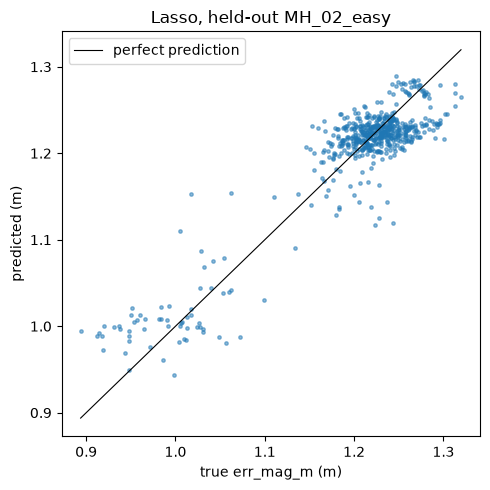

In [ ]:
lasso = preds[preds["model"] == "lasso"]
for seq in seqs:
    g = lasso[lasso["test_seq"] == seq]
    lo, hi = g[["y", "y_hat"]].min().min(), g[["y", "y_hat"]].max().max()
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(g["y"], g["y_hat"], s=6, alpha=0.5)
    ax.plot([lo, hi], [lo, hi], color="black", lw=0.8, label="perfect prediction")
    ax.set_xlabel("true err_mag_m (m)"); ax.set_ylabel("predicted (m)")
    ax.set_title(f"Lasso, held-out {seq}")
    ax.legend(); fig.tight_layout(); fig.savefig(FIG / f"pred_vs_true_lasso_{seq}.png", dpi=150); plt.show()

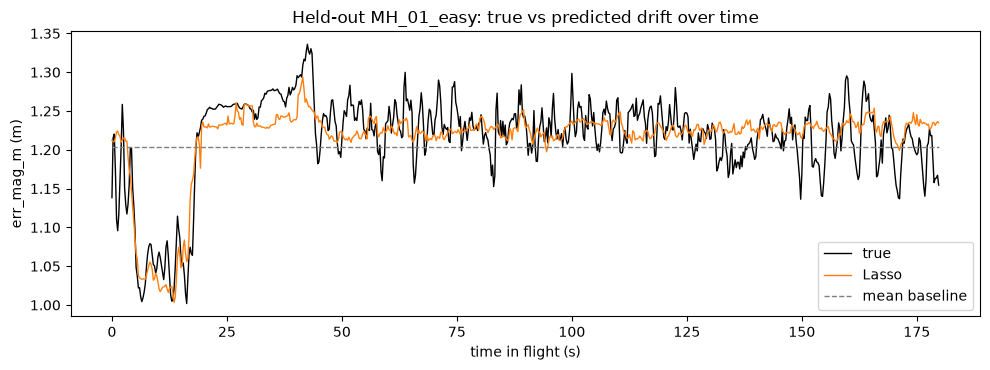

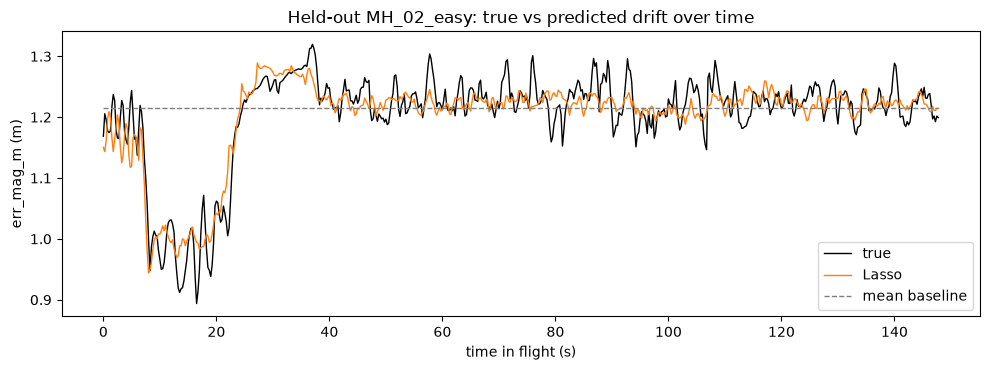

In [ ]:
for seq in seqs:
    g = preds[preds["test_seq"] == seq]
    t = (g["t_start_ns"] - g["t_start_ns"].min()) / 1e9
    truth = g[g["model"] == "lasso"]
    tt = t[truth.index]
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.plot(tt, truth["y"], color="black", lw=1, label="true")
    ax.plot(tt, truth["y_hat"], color="C1", lw=1, label="Lasso")
    ax.plot(tt, g[g["model"] == "mean"]["y_hat"].to_numpy(), color="C7", ls="--", lw=1, label="mean baseline")
    ax.set_xlabel("time in flight (s)"); ax.set_ylabel("err_mag_m (m)")
    ax.set_title(f"Held-out {seq}: true vs predicted drift over time")
    ax.legend(); fig.tight_layout(); fig.savefig(FIG / f"drift_over_time_{seq}.png", dpi=150); plt.show()

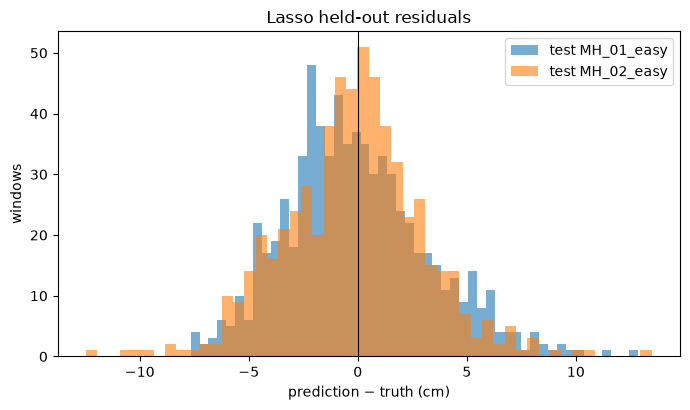

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for seq in seqs:
    r = lasso[lasso["test_seq"] == seq]
    ax.hist((r["y_hat"] - r["y"]) * 100, bins=50, alpha=0.6, label=f"test {seq}")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("prediction − truth (cm)"); ax.set_ylabel("windows")
ax.set_title("Lasso held-out residuals")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "residuals_lasso.png", dpi=150); plt.show()

## 5. Where do the errors happen?

Notebook 05 showed the start of each flight (take-off) behaves differently. Here the held-out flight is split into its first 20% of windows (≈ take-off) and the rest.

In [ ]:
rows = []
for (seq, name), g in preds.groupby(["test_seq", "model"], sort=False):
    g = g.sort_values("t_start_ns")
    cut = int(0.2 * len(g))
    for part, h in [("first 20% (take-off)", g.iloc[:cut]), ("remaining 80%", g.iloc[cut:])]:
        rows.append({"test_seq": seq, "model": name, "part": part,
                     "MAE (cm)": np.mean(np.abs(h["y_hat"] - h["y"])) * 100})
segments = pd.DataFrame(rows).pivot_table(index=["test_seq", "part"], columns="model",
                                          values="MAE (cm)", sort=False)[NAMES]
segments.round(2)

model                             mean   ols  ridge  lasso
test_seq   part                                           
MH_01_easy first 20% (take-off)   8.77  4.42   3.91   2.85
           remaining 80%          3.30  2.79   2.52   2.53
MH_02_easy first 20% (take-off)  13.03  4.91   4.26   3.60
           remaining 80%          2.57  2.36   2.19   2.12

In [ ]:
share = []
for (seq, name), g in preds[preds["model"] == "lasso"].groupby(["test_seq", "model"]):
    g = g.sort_values("t_start_ns")
    err = (g["y_hat"] - g["y"]).abs().to_numpy()
    cut = int(0.2 * len(g))
    share.append({"test_seq": seq, "share of total |error| in first 20%": err[:cut].sum() / err.sum()})
pd.DataFrame(share).round(3)

,test_seq,share of total |error| in first 20%
0,MH_01_easy,0.220
1,MH_02_easy,0.297


In [ ]:
from sklearn.metrics import r2_score
rows = []
for (seq, name), g in preds.groupby(["test_seq", "model"], sort=False):
    if name == "mean":
        continue
    g = g.sort_values("t_start_ns")
    cut = int(0.2 * len(g))
    rows.append({"test_seq": seq, "model": name,
                 "R² first 20%": r2_score(g["y"].iloc[:cut], g["y_hat"].iloc[:cut]),
                 "R² remaining 80%": r2_score(g["y"].iloc[cut:], g["y_hat"].iloc[cut:]),
                 "R² whole flight": r2_score(g["y"], g["y_hat"])})
pd.DataFrame(rows).set_index(["test_seq", "model"]).round(2)

R² first 20%  R² remaining 80%  R² whole flight
test_seq   model                                                 
MH_01_easy ols            0.50             -0.17             0.40
           ridge          0.77              0.10             0.63
           lasso          0.86              0.10             0.68
MH_02_easy ols            0.70              0.00             0.76
           ridge          0.77              0.11             0.80
           lasso          0.84              0.17             0.84

**Read the R² with care.** Most of the drift variation in a flight is the take-off dip (≈ 1.0 m vs ≈ 1.22 m in normal flight; see the over-time plots). The models track that dip well (R² 0.84–0.86 for Lasso in the first 20%), and it dominates the whole-flight R². In normal flight the models explain only a small part of the fast window-to-window wiggles (Lasso R² 0.10–0.17): their predictions are much smoother than the truth. Lasso's MAE there is still below the mean baseline (2.53 vs 3.30 cm on MH_01, 2.12 vs 2.57 cm on MH_02).

## Summary

- **Lasso is the best model**: held-out MAE 2.50 cm vs 4.53 cm for the mean baseline (45% lower), R² 0.76, almost no bias (−0.12 cm). Ridge is close (2.70 cm, R² 0.72); OLS is clearly worse (2.99 cm, R² 0.58).
- **Regularisation works against over-fitting**: held-out/train MAE ratio drops from 1.81 (OLS) to 1.38 (Ridge) and 1.24 (Lasso).
- **Both flights** are predicted, MH_02 better (R² 0.84) than MH_01 (R² 0.68).
- **The models capture the slow, large changes** (the take-off dip) well, but **not the fast fluctuations in normal flight** (R² ≈ 0.1–0.17 there). The headline R² is driven by take-off.
- Take-off is also where the largest absolute errors are: 22% / 30% of Lasso's total error falls in the first 20% of each flight.

Open directions: the physics feature (drift from a calibrated IMU bias), a non-linear model (Random Forest), and features that react to faster changes within normal flight.